# Mapping calibrated signals to positions

A two-parameter sigmoid can turn a score into an estimated probability:

$$
q(f)=\frac{1}{1+\exp(Af+B)}.
$$

Here, $f$ is the original score, $q(f)$ is the calibrated probability of the positive outcome, and $A$ and $B$ set the slope and location of the sigmoid. The two values are estimated on observations that were not used to fit the original prediction rule.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("22_position_sizing");
using CSV, TOML, Printf
using Distributions: Normal,cdf,quantile
source_path = dataset_path("fred_sp500")
@assert isfile(source_path)
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
logs = log.(prices)
log_returns = vcat(NaN,diff(logs))
simple_returns = vcat(NaN,prices[2:end]./prices[1:end-1].-1)
data_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
data_provenance = DataFrame("Field"=>["Series","Provider","Source","Retrieved","First price","Last price","Price observations"],"Value"=>["S&P 500","Federal Reserve Bank of St. Louis",data_url,"2026-09-28",string(first(dates)),string(last(dates)),string(length(prices))])
violet,muted = "#C084FC","#9CA3AF"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter22-"*replace(name,"_"=>"-"))
date_ticks(values;step=2) = let ticks=filter(date->first(values)<=date<=last(values),Date.(collect(year(first(values)):step:year(last(values))),1,1)); (Dates.value.(ticks),string.(year.(ticks))) end
isclose(x,y;atol=1e-8,rtol=1e-5) = isapprox(x,y;atol,rtol)
save_data(DataFrame(date=dates,price=prices,log_return=log_returns,simple_return=simple_returns),paths,"calibration_observations");
using RiskLabAI.Backtest: probability_bet_size,average_bet_sizes,avg_active_signals,discrete_signal,generate_signal,strategy_bet_sizing,bet_size_sigmoid,compute_sigmoid_width,target_position,limit_price,inverse_price,kelly_bet_fraction,distributionally_robust_kelly_fraction,expected_calibration_error
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
feature_names = ["Five-day return","Twenty-day return","Twenty-day variation","Distance from sixty-day mean"]
x = hcat([logs[index]-logs[index-5] for index in 60:length(logs)],[logs[index]-logs[index-20] for index in 60:length(logs)],[std(log_returns[index-19:index]) for index in 60:length(logs)],[logs[index]-mean(logs[index-59:index]) for index in 60:length(logs)])
y = [index<length(logs) ? Int(log_returns[index+1]>0) : 0 for index in 60:length(logs)]
model_dates = dates[60:end]
train_end,calibration_end = floor(Int,.6length(y)),floor(Int,.8length(y))
train,calibration,test = 1:train_end,train_end+1:calibration_end,calibration_end+1:length(y)
base_model = BookLogisticLBFGS.fit_logistic(x[train,:],y[train];C=1.,class_weight=:balanced,max_iter=2000)
validation_probabilities = BookEstimators.predict_proba(base_model,x[calibration,:])[:,2]
test_probabilities = BookEstimators.predict_proba(base_model,x[test,:])[:,2]
validation_outcomes,test_outcomes = y[calibration],y[test]
stretch(values) = 1 ./ (1 .+exp.(-12 .*log.(clamp.(values,1e-6,1-1e-6)./(1 .-clamp.(values,1e-6,1-1e-6)))))
logit_matrix(values) = reshape(log.(clamp.(values,1e-4,1-1e-4)./(1 .-clamp.(values,1e-4,1-1e-4))),:,1)
distorted_validation,distorted_test = stretch(validation_probabilities),stretch(test_probabilities)
raw_calibrator = BookLogisticLBFGS.fit_logistic(logit_matrix(validation_probabilities),validation_outcomes;C=1e6)
distortion_calibrator = BookLogisticLBFGS.fit_logistic(logit_matrix(distorted_validation),validation_outcomes;C=1e6)
calibrated_test = BookEstimators.predict_proba(raw_calibrator,logit_matrix(test_probabilities))[:,2]
repaired_test = BookEstimators.predict_proba(distortion_calibrator,logit_matrix(distorted_test))[:,2]
brier_score(values,outcomes) = mean((values.-outcomes).^2)
function calibration_bins(values,outcomes,name)
    rows = NamedTuple[]
    edges = collect(0:10).*0.1
    for index in 1:10
        selected = findall((index==1 ? values.>=edges[index] : values.>edges[index]).&(values.<=edges[index+1]))
        isempty(selected) && continue
        band = index==1 ? "(-0.001, 0.1]" : "("*@sprintf("%.1f",edges[index])*", "*@sprintf("%.1f",edges[index+1])*"]"
        push!(rows,(Method=name,Band=band,Observations=length(selected),average=mean(values[selected]),frequency=mean(outcomes[selected])))
    end
    result = DataFrame(rows)
    rename!(result,["Method","Band","Observations","Average probability","Observed frequency"])
    return result
end
save_data(hcat(DataFrame(date=model_dates),DataFrame(x,feature_names),DataFrame(outcome=y)),paths,"calibration_model_data")
save_data(DataFrame(date=model_dates[calibration],probability=validation_probabilities,distorted=distorted_validation,outcome=validation_outcomes),paths,"calibration_training_probabilities")
save_data(DataFrame(date=model_dates[test],original=test_probabilities,calibrated=calibrated_test,distorted=distorted_test,repaired=repaired_test,outcome=test_outcomes),paths,"calibration_test_probabilities")
fit_diagnostics = DataFrame(model=["Base","Platt on original","Platt after overconfidence"],iterations=[base_model.iterations,raw_calibrator.iterations,distortion_calibrator.iterations],objective=[base_model.objective,raw_calibrator.objective,distortion_calibrator.objective],gradient=[base_model.gradient_norm,raw_calibrator.gradient_norm,distortion_calibrator.gradient_norm])
save_data(fit_diagnostics,paths,"calibration_fit_diagnostics")
save_data(DataFrame(feature=vcat(feature_names,["Intercept"]),coefficient=vcat(base_model.coefficients,[base_model.intercept])),paths,"base_logistic_coefficients")
save_data(DataFrame(model=["Original","Distorted"],slope=[raw_calibrator.coefficients[1],distortion_calibrator.coefficients[1]],intercept=[raw_calibrator.intercept,distortion_calibrator.intercept]),paths,"platt_coefficients");


## Public Probability Study

Calibration error and squared probability error summarize two different aspects of a probability forecast:

$$
ECE=\sum_{j=1}^{J}\frac{n_j}{T}\left|\overline y_j-\overline q_j\right|,
\qquad
BS=\frac{1}{T}\sum_{t=1}^{T}(q_t-y_t)^2.
$$

Here, $J$ is the number of probability bands, $n_j$ is the number of observations in band $j$, $T$ is the test-sample size, $\overline y_j$ is the observed positive frequency in the band, $\overline q_j$ is its average forecast probability, $q_t$ is forecast $t$, $y_t$ is its zero-one outcome, $ECE$ is expected calibration error, and $BS$ is the Brier score.

Row,Field,Value
,String,String
1,Series,S&P 500
2,Provider,Federal Reserve Bank of St. Louis
3,Source,https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31
4,Retrieved,2026-09-28
5,First price,2016-09-26
6,Last price,2025-12-31
7,Price observations,2330


Row,Block,First date,Last date,Observations,Positive share
,String,Date,Date,Int64,Float64
1,Training,2016-12-19,2022-05-17,1362,0.5558
2,Calibration,2022-05-18,2024-03-08,454,0.508811
3,Test,2024-03-11,2025-12-31,455,0.571429


Row,Method,Brier score,Calibration error,Mean probability,Smallest probability,Largest probability
,String,Float64,Float64,Float64,Float64,Float64
1,Original,0.250056,0.0717279,0.499701,0.489053,0.520017
2,Platt on original,0.248819,0.0626179,0.508811,0.508807,0.508813
3,Known overconfidence,0.252346,0.0781739,0.496284,0.371563,0.723387
4,Platt after overconfidence,0.248798,0.0624366,0.508992,0.502254,0.512521


Row,Method,Band,Observations,Average probability,Observed frequency
,String,String,Int64,Float64,Float64
1,Original,"(0.4, 0.5]",294,0.497706,0.568027
2,Original,"(0.5, 0.6]",161,0.503343,0.57764
3,Known overconfidence,"(0.3, 0.4]",5,0.388233,0.8
4,Known overconfidence,"(0.4, 0.5]",289,0.474019,0.564014
5,Known overconfidence,"(0.5, 0.6]",149,0.531459,0.577181
6,Known overconfidence,"(0.6, 0.7]",10,0.626008,0.6
7,Known overconfidence,"(0.7, 0.8]",2,0.714567,0.5
8,Repaired overconfidence,"(0.5, 0.6]",455,0.508992,0.571429


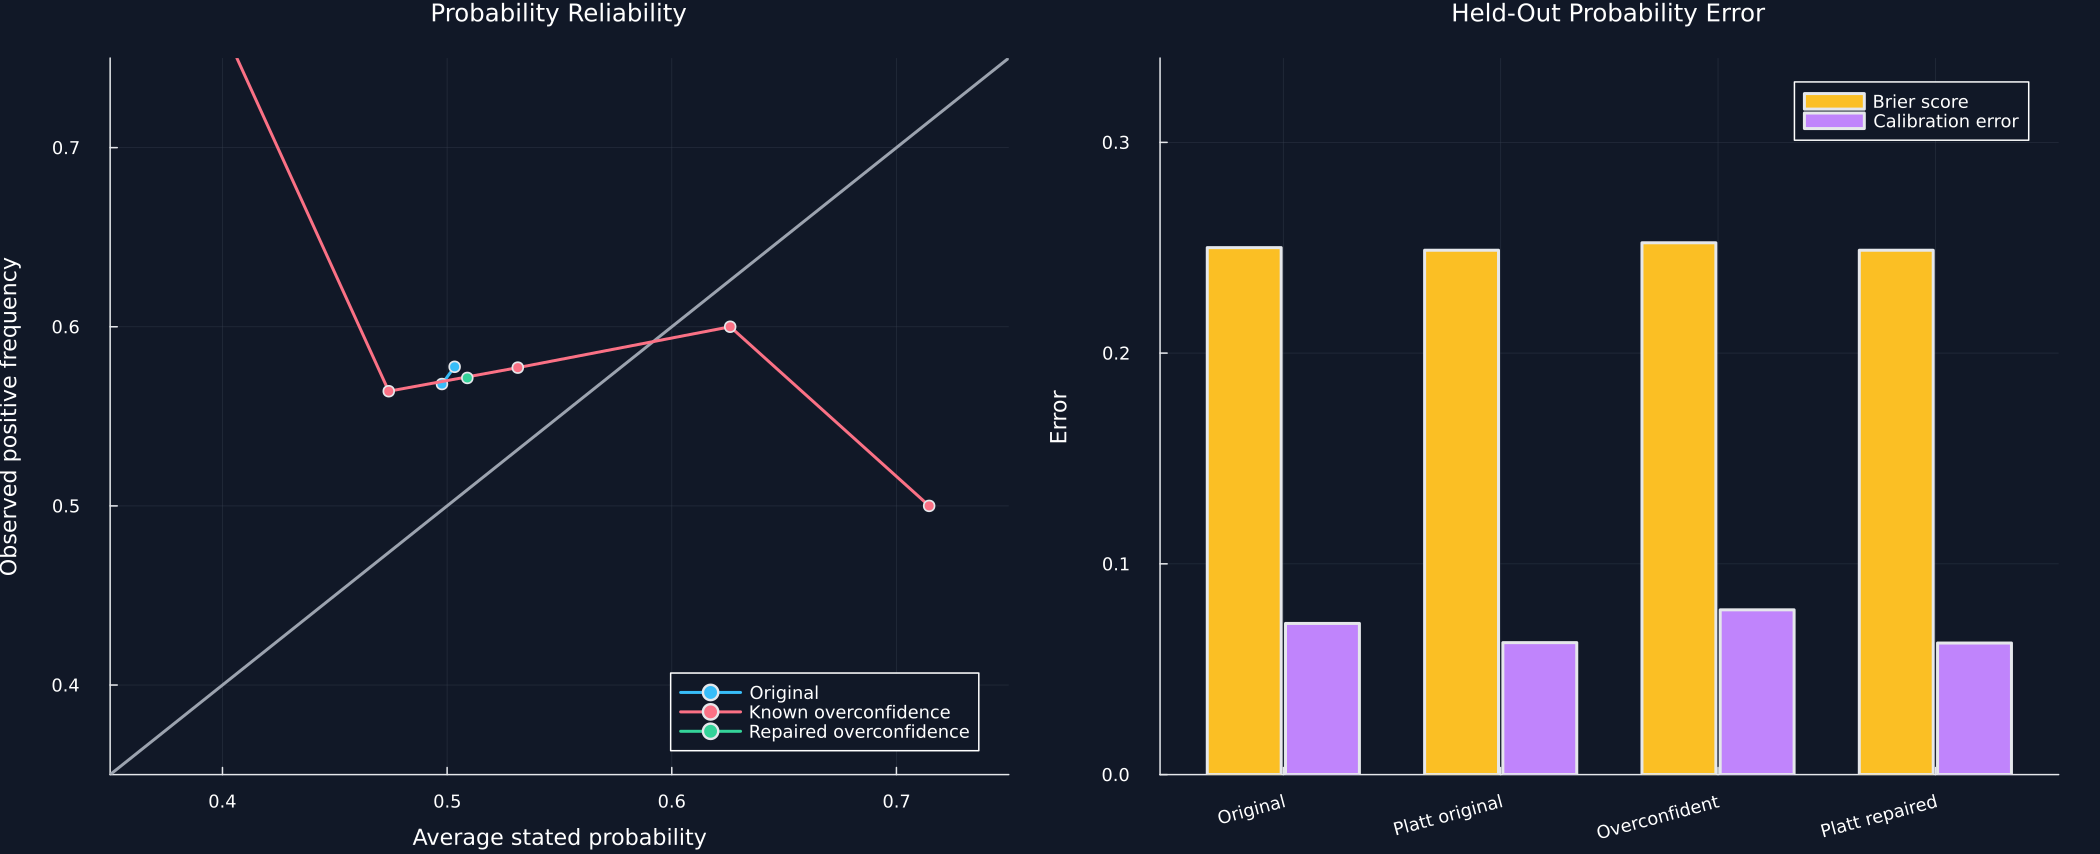

In [2]:
split_summary = DataFrame("Block"=>["Training","Calibration","Test"],"First date"=>[first(model_dates[block]) for block in [train,calibration,test]],"Last date"=>[last(model_dates[block]) for block in [train,calibration,test]],"Observations"=>length.([train,calibration,test]),"Positive share"=>[mean(y[block]) for block in [train,calibration,test]])
method_names = ["Original","Platt on original","Known overconfidence","Platt after overconfidence"]
probability_sets = [test_probabilities,calibrated_test,distorted_test,repaired_test]
calibration_summary = DataFrame("Method"=>method_names,"Brier score"=>[brier_score(values,test_outcomes) for values in probability_sets],"Calibration error"=>[expected_calibration_error(values,test_outcomes,10) for values in probability_sets],"Mean probability"=>mean.(probability_sets),"Smallest probability"=>minimum.(probability_sets),"Largest probability"=>maximum.(probability_sets))
public_calibration_bins = vcat(calibration_bins(test_probabilities,test_outcomes,"Original"),calibration_bins(distorted_test,test_outcomes,"Known overconfidence"),calibration_bins(repaired_test,test_outcomes,"Repaired overconfidence"))
table(data_provenance,"calibration_data_provenance","Public observations used for the probability study.")
table(split_summary,"calibration_split_summary","Time-ordered training, calibration, and test blocks.")
table(calibration_summary,"public_calibration_summary","Out-of-sample errors before and after sigmoid calibration.")
table(public_calibration_bins,"public_calibration_bins","Probability bands and observed frequencies in the public test block.")
p1 = plot([0.,1.],[0.,1.];color=muted,label="",xlims=(.35,.75),ylims=(.35,.75),xlabel="Average stated probability",ylabel="Observed positive frequency",title="Probability Reliability",legend=:bottomright)
for (name,color) in zip(["Original","Known overconfidence","Repaired overconfidence"],[palette.cyan,palette.rose,palette.green])
    subset = public_calibration_bins[public_calibration_bins.Method.==name,:]
    plot!(p1,subset[!,"Average probability"],subset[!,"Observed frequency"];marker=:circle,color,label=name)
end
p2 = bar((1:4).-0.18,calibration_summary[!,"Brier score"];bar_width=.34,color=palette.amber,label="Brier score",xticks=(1:4,["Original","Platt original","Overconfident","Platt repaired"]),xrotation=15,ylabel="Error",title="Held-Out Probability Error",legend=:topright,ylims=(0,.34))
bar!(p2,(1:4).+0.18,calibration_summary[!,"Calibration error"];bar_width=.34,color=violet,label="Calibration error")
save_figure(plot(p1,p2;layout=(1,2),size=(1400,570)),paths,"calibration_reliability")


## Probability to Signed Size

A class probability is first compared with equal odds and then mapped to a signed size:

$$
z(p,K)=\frac{p-K^{-1}}{\sqrt{p(1-p)}},
\qquad
m=s\left[2\Phi\!\left(z(p,K)\right)-1\right].
$$

Here, $p$ is the probability assigned to the predicted class, $K$ is the number of classes, $z(p,K)$ is its standardized distance from equal odds, $s\in\{-1,1\}$ is the predicted side, $\Phi$ is the standard normal distribution function, and $m\in[-1,1]$ is the signed position size.

Row,Predicted-class probability,Standardized score,Long size,Short size,Long size at 0.1 steps
,Float64,Float64,Float64,Float64,Float64
1,0.5,0.0,0.0,-0.0,0.0
2,0.52,0.040032,0.0319324,-0.0319324,0.0
3,0.55,0.100504,0.0800556,-0.0800556,0.1
4,0.6,0.204124,0.161744,-0.161744,0.2
5,0.7,0.436436,0.337479,-0.337479,0.3
6,0.8,0.75,0.546745,-0.546745,0.5
7,0.9,1.33333,0.817578,-0.817578,0.8
8,0.99,4.92469,0.999999,-0.999999,1.0


Row,Quantity,Value
,String,Float64
1,Test observations,455.0
2,Long directions,161.0
3,Short directions,294.0
4,Mean absolute size,0.00425332
5,Largest absolute size,0.0319593
6,Mean confidence,0.502665


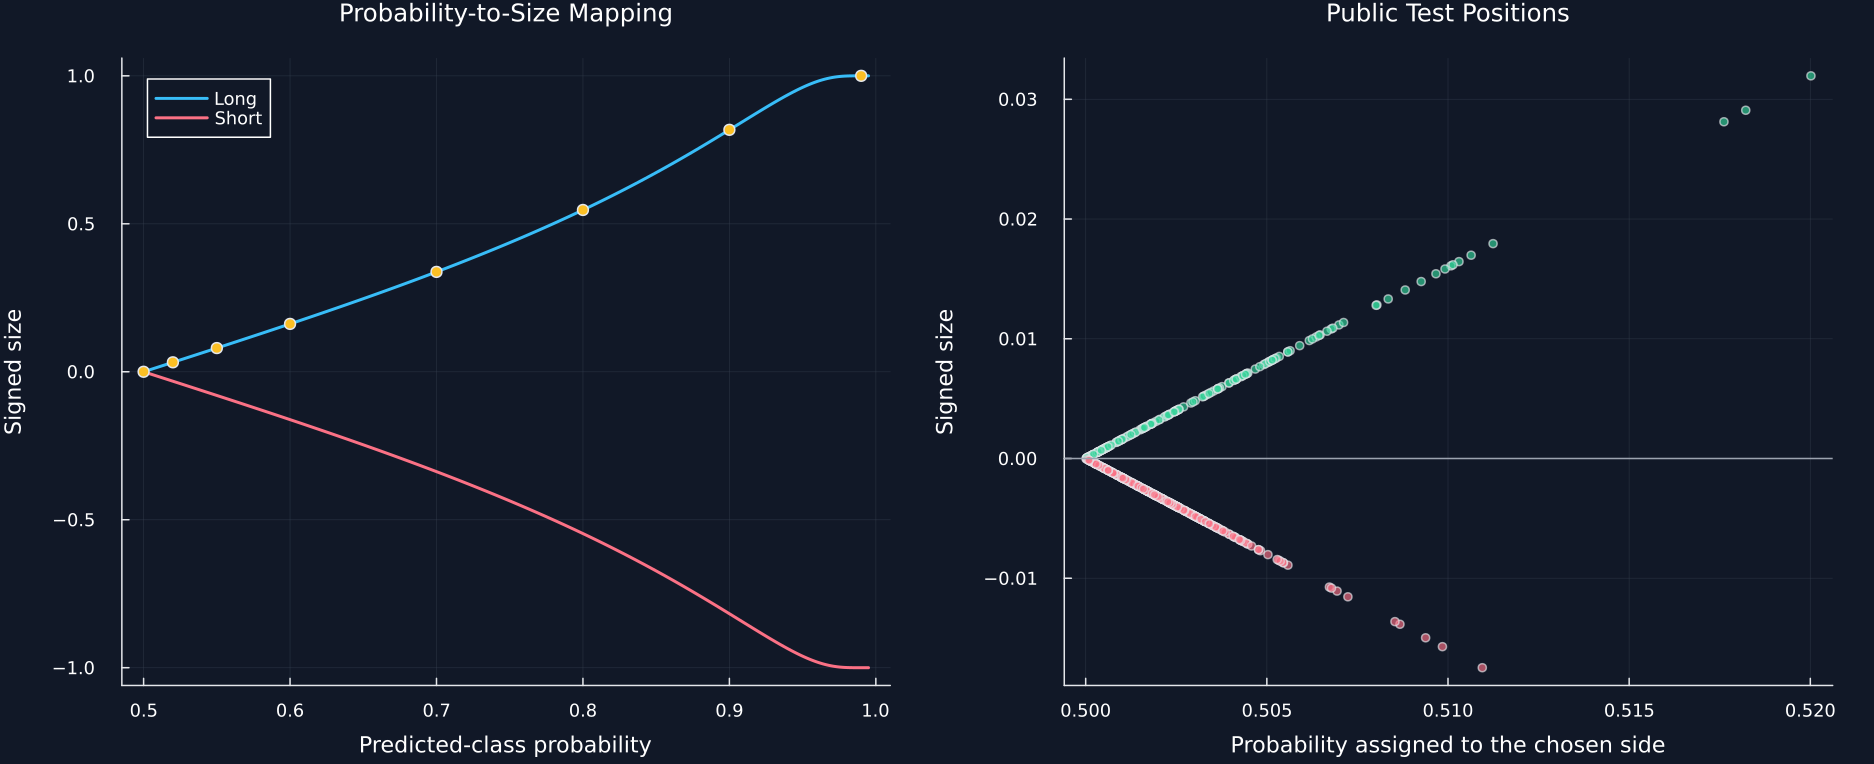

In [3]:
probability_grid = [.50,.52,.55,.60,.70,.80,.90,.99]
score_grid = (probability_grid.-.5)./sqrt.(probability_grid.*(1 .-probability_grid))
positive_sizes = probability_bet_size(score_grid,ones(length(score_grid)))
size_mapping = DataFrame("Predicted-class probability"=>probability_grid,"Standardized score"=>score_grid,"Long size"=>positive_sizes,"Short size"=>-positive_sizes,"Long size at 0.1 steps"=>discrete_signal(positive_sizes,.1))
test_sides = ifelse.(test_probabilities.>=.5,1,-1)
test_confidence = ifelse.(test_sides.==1,test_probabilities,1 .-test_probabilities)
test_scores = (test_confidence.-.5)./sqrt.(test_confidence.*(1 .-test_confidence))
test_sizes = probability_bet_size(test_scores,test_sides)
public_size_summary = DataFrame("Quantity"=>["Test observations","Long directions","Short directions","Mean absolute size","Largest absolute size","Mean confidence"],"Value"=>[length(test_sizes),sum(test_sides.==1),sum(test_sides.==-1),mean(abs.(test_sizes)),maximum(abs,test_sizes),mean(test_confidence)])
table(size_mapping,"probability_size_mapping","Probability-to-size mapping for a two-class decision.")
table(public_size_summary,"public_size_summary","Position-size summary for the public test block.")
dense_probabilities = collect(range(.5,.995;length=300))
dense_scores = (dense_probabilities.-.5)./sqrt.(dense_probabilities.*(1 .-dense_probabilities))
dense_sizes = probability_bet_size(dense_scores,ones(300))
save_data(DataFrame(probability=dense_probabilities,score=dense_scores,long=dense_sizes,short=-dense_sizes),paths,"probability_size_curves")
save_data(DataFrame(date=model_dates[test],side=test_sides,confidence=test_confidence,score=test_scores,size=test_sizes),paths,"public_test_positions")
p1 = plot(dense_probabilities,dense_sizes;color=palette.cyan,label="Long",xlabel="Predicted-class probability",ylabel="Signed size",title="Probability-to-Size Mapping",legend=:topleft)
plot!(p1,dense_probabilities,-dense_sizes;color=palette.rose,label="Short")
scatter!(p1,probability_grid,positive_sizes;color=palette.amber,label="")
p2 = scatter(test_confidence,test_sizes;color=ifelse.(test_sides.>0,palette.green,palette.rose),alpha=.65,markersize=3,label="",xlabel="Probability assigned to the chosen side",ylabel="Signed size",title="Public Test Positions")
hline!(p2,[0.];color=muted,label="",linewidth=1)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,510)),paths,"probability_size_map")


## Aggregating concurrent discrete signals

Overlapping positions are averaged and then placed on a declared size grid:

$$
\overline m_t=\frac{1}{|A_t|}\sum_{i\in A_t}m_i,
\qquad
m_t^{(d)}=\operatorname{clip}_{[-1,1]}\!\left(d\,\operatorname{round}\!\left(\frac{\overline m_t}{d}\right)\right).
$$

Here, $A_t$ is the set of positions active at time $t$, $|A_t|$ is its size, $m_i$ is the signed size of active position $i$, $\overline m_t$ is their average, $d\in(0,1]$ is the size step, and $m_t^{(d)}$ is the bounded discrete position.

Row,Date,Average active size,Discrete active size,Active positions
,Date,Float64,Float64,Int64
1,2024-03-11,-0.000477179,-0.0,1
2,2024-04-02,-0.000262119,-0.0,2
3,2024-04-09,-4.70583e-5,-0.0,1
4,2024-04-23,0.00173661,0.0,2
5,2024-04-30,0.00352029,0.0,1
6,2024-05-14,-0.000108932,-0.0,2
7,2024-05-21,-0.00373815,-0.0,1
8,2024-06-05,-0.00392479,-0.0,2
9,2024-06-12,-0.00411143,-0.0,1


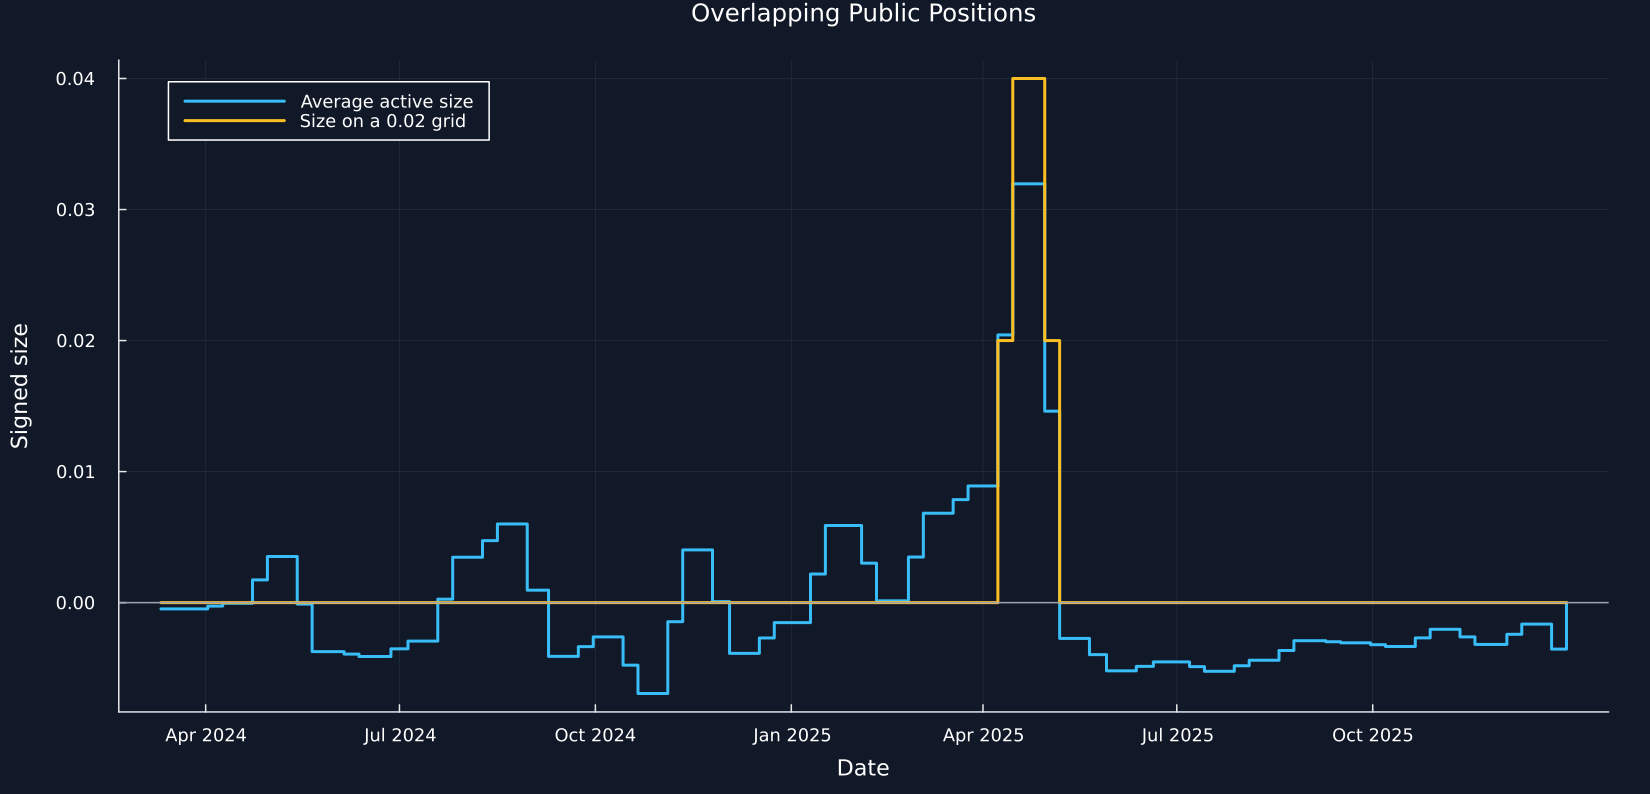

In [4]:
selected_locations = collect(1:15:length(test))
event_starts = model_dates[test][selected_locations]
event_ends = model_dates[test][min.(selected_locations.+20,length(test))]
event_probabilities,event_predictions = test_confidence[selected_locations],test_sides[selected_locations]
event_scores = (event_probabilities.-.5)./sqrt.(event_probabilities.*(1 .-event_probabilities))
individual_signals = probability_bet_size(event_scores,event_predictions)
active_dates,active_average = avg_active_signals(event_starts,event_ends,individual_signals)
discrete_active = discrete_signal(active_average,.02)
generated_dates,generated_active = generate_signal(event_starts,event_ends,nothing,event_probabilities,event_predictions,2,.02)
active_signal_table = DataFrame("Date"=>active_dates,"Average active size"=>active_average,"Discrete active size"=>discrete_active,"Active positions"=>[sum((event_starts.<=date).&(date.<event_ends)) for date in active_dates])
table(active_signal_table,"active_signal_table","Average and discrete sizes as public-data positions overlap.")
save_data(DataFrame(start=event_starts,finish=event_ends,probability=event_probabilities,side=event_predictions,score=event_scores,signal=individual_signals),paths,"position_events")
quarter_dates = filter(date->first(active_dates)<=date<=last(active_dates),collect(Date(year(first(active_dates)),1,1):Month(3):Date(year(last(active_dates)),12,1)))
p = plot(Dates.value.(active_dates),active_average;seriestype=:steppost,color=palette.cyan,label="Average active size",xticks=(Dates.value.(quarter_dates),Dates.format.(quarter_dates,"u yyyy")),xlabel="Date",ylabel="Signed size",title="Overlapping Public Positions",legend=:topleft,size=(1100,530))
plot!(p,Dates.value.(active_dates),discrete_active;seriestype=:steppost,color=palette.amber,label="Size on a 0.02 grid")
hline!(p,[0.];color=muted,linewidth=1,label="")
save_figure(p,paths,"active_signal_path")


## Dynamic Price Mappings

A price gap can be mapped to a bounded size and an integer target position:

$$
m(w,x)=\frac{x}{\sqrt{w+x^2}},
\qquad
\widehat q=\operatorname{int}\!\left(Qm(w,f-p)\right),
\qquad
w=x_*^2\left(m_*^{-2}-1\right).
$$

Here, $x=f-p$ is the gap between forecast price $f$ and current price $p$, $w>0$ controls how quickly size approaches its bounds, $m(w,x)$ is the continuous size, $Q$ is the largest absolute position, $\widehat q$ is the integer target position, and the chosen pair $(x_*,m_*)$ calibrates $w$.

Row,Market price,Forecast price,Price gap,Continuous size,Target position,Average limit price
,Float64,Float64,Float64,Float64,Int64,Float64
1,95.0,115.0,20.0,0.986763,98,112.227
2,100.0,115.0,15.0,0.976824,97,112.366
3,105.0,115.0,10.0,0.95,95,112.567
4,110.0,115.0,5.0,0.835619,83,113.219
5,115.0,115.0,0.0,0.0,0,115.0
6,120.0,115.0,-5.0,-0.835619,-83,113.219
7,125.0,115.0,-10.0,-0.95,-95,112.567
8,130.0,115.0,-15.0,-0.976824,-97,112.366
9,135.0,115.0,-20.0,-0.986763,-98,112.227


Row,Quantity,Value
,String,Float64
1,Calibration gap,10.0
2,Calibration size,0.95
3,Width,10.8033
4,Forecast price,115.0
5,Market price,100.0
6,Maximum position,100.0
7,Target position,97.0
8,Average limit price,112.366


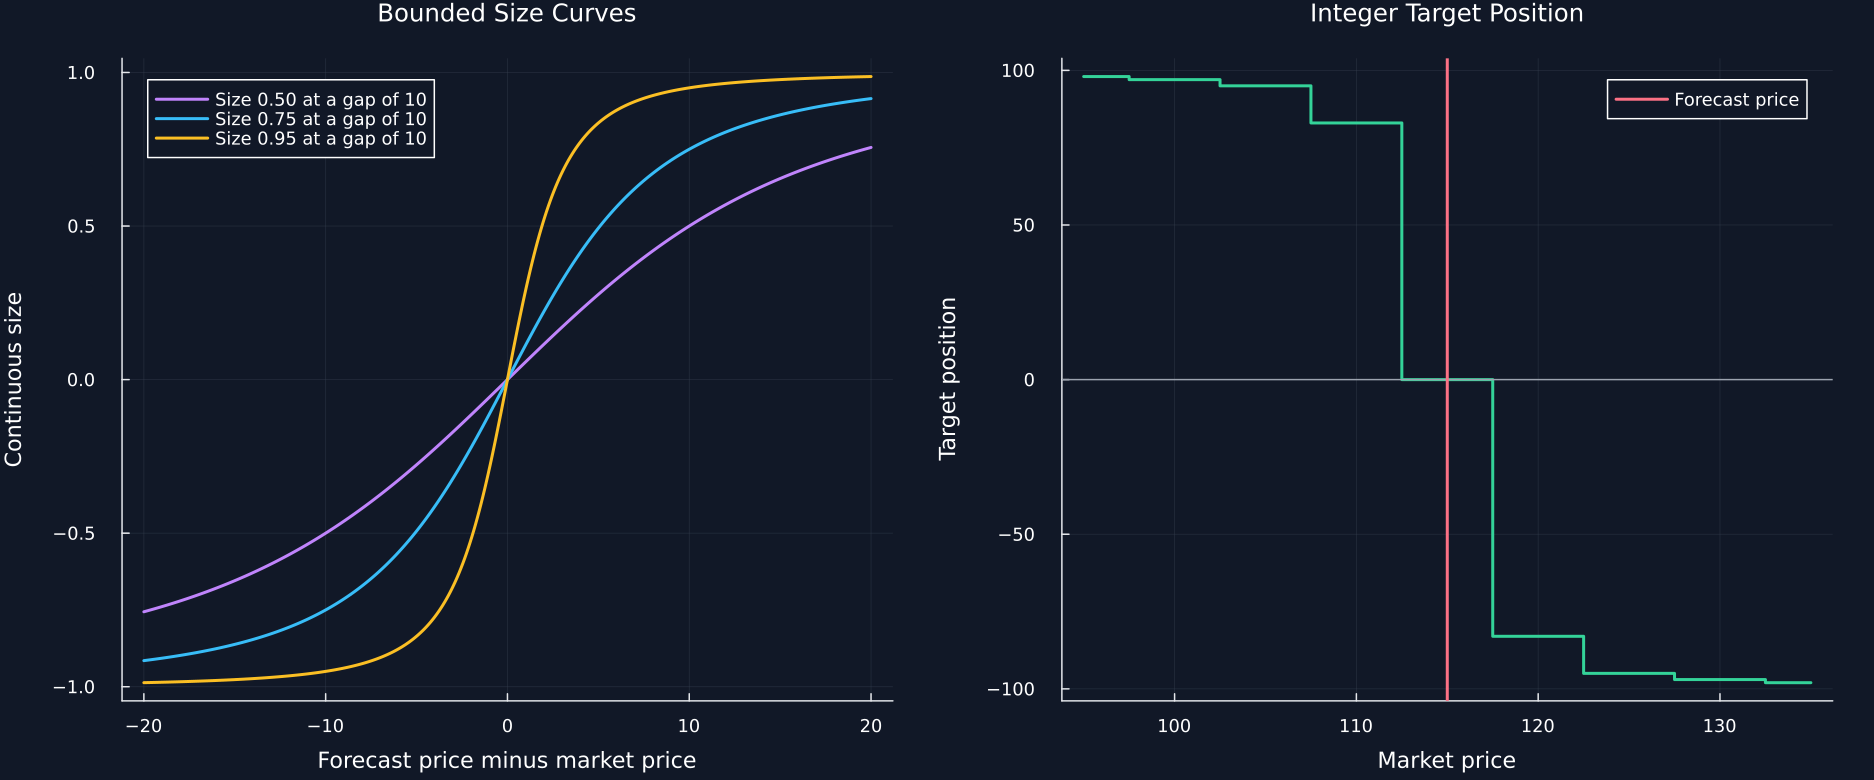

In [5]:
width = compute_sigmoid_width(10.,.95)
forecast_price,maximum_position,current_position = 115.,100,0
market_prices = collect(95.:5.:135.)
targets = [target_position(width,forecast_price,price,maximum_position) for price in market_prices]
dynamic_position_table = DataFrame("Market price"=>market_prices,"Forecast price"=>fill(forecast_price,9),"Price gap"=>forecast_price.-market_prices,"Continuous size"=>[bet_size_sigmoid(width,forecast_price-price) for price in market_prices],"Target position"=>targets,"Average limit price"=>[limit_price(target,current_position,forecast_price,width,maximum_position) for target in targets])
preliminary_dynamic_reproduction = DataFrame("Quantity"=>["Calibration gap","Calibration size","Width","Forecast price","Market price","Maximum position","Target position","Average limit price"],"Value"=>[10.,.95,width,115.,100.,100,target_position(width,115.,100.,100),limit_price(target_position(width,115.,100.,100),0,115.,width,100)])
table(dynamic_position_table,"dynamic_position_table","Target positions and average limit prices for a fixed forecast.")
table(preliminary_dynamic_reproduction,"preliminary_dynamic_reproduction","Reproduction of the dynamic-position numerical example.")
gaps = collect(range(-20.,20.;length=400))
curve_rows = NamedTuple[]
p1 = plot(;xlabel="Forecast price minus market price",ylabel="Continuous size",title="Bounded Size Curves",legend=:topleft)
for (chosen,color) in zip([.50,.75,.95],[violet,palette.cyan,palette.amber])
    chosen_width = compute_sigmoid_width(10.,chosen)
    values = [bet_size_sigmoid(chosen_width,gap) for gap in gaps]
    plot!(p1,gaps,values;color,label=@sprintf("Size %.2f at a gap of 10",chosen))
    append!(curve_rows,[(size=chosen,gap=gap,value=value) for (gap,value) in zip(gaps,values)])
end
save_data(DataFrame(curve_rows),paths,"dynamic_sigmoid_curves")
p2 = plot(market_prices,targets;seriestype=:stepmid,color=palette.green,label="",xlabel="Market price",ylabel="Target position",title="Integer Target Position",legend=:topright)
hline!(p2,[0.];color=muted,linewidth=1,label="")
vline!(p2,[forecast_price];color=palette.rose,label="Forecast price")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,520)),paths,"dynamic_sigmoid_positions")


## Growth Fractions under Probability Uncertainty

A binary Kelly fraction and a lower-confidence version are given by:

$$
f_K(p,b)=\operatorname{clip}_{[0,f_{\max}]}\!\left(\frac{p(b+1)-1}{b}\right),
\qquad
p_L=\widehat p-z_c\sqrt{\frac{\widehat p(1-\widehat p)}{n}},
\qquad
f_R=f_K(p_L,b).
$$

Here, $p$ is a known win probability, $b>0$ is the net win per unit lost on failure, $f_K$ is the Kelly wealth fraction, $f_{\max}$ is its upper bound, $\widehat p$ is an estimated win probability, $n$ is the number of observations behind it, $z_c$ sets the lower-confidence adjustment, $p_L$ is the pessimistic probability, and $f_R$ is the uncertainty-adjusted fraction.

Row,Win probability,Observations,Full Kelly fraction,Uncertainty-adjusted fraction
,Float64,Int64,Float64,Float64
1,0.5,25,0.0,0.0
2,0.5,100,0.0,0.0
3,0.5,1000,0.0,0.0
4,0.5,1000000,0.0,0.0
5,0.55,25,0.1,0.0
6,0.55,100,0.1,0.000501256
7,0.55,1000,0.1,0.0685357
8,0.55,1000000,0.1,0.099005
9,0.6,25,0.2,0.00404082


Row,Probability quantile,Predicted-class probability,Full Kelly fraction,Uncertainty-adjusted fraction
,String,Float64,Float64,Float64
1,10 percent,0.500367,0.000733429,0.0
2,25 percent,0.501031,0.00206221,0.0
3,50 percent,0.502133,0.00426627,0.0
4,75 percent,0.503414,0.00682735,0.0
5,90 percent,0.505249,0.0104972,0.0


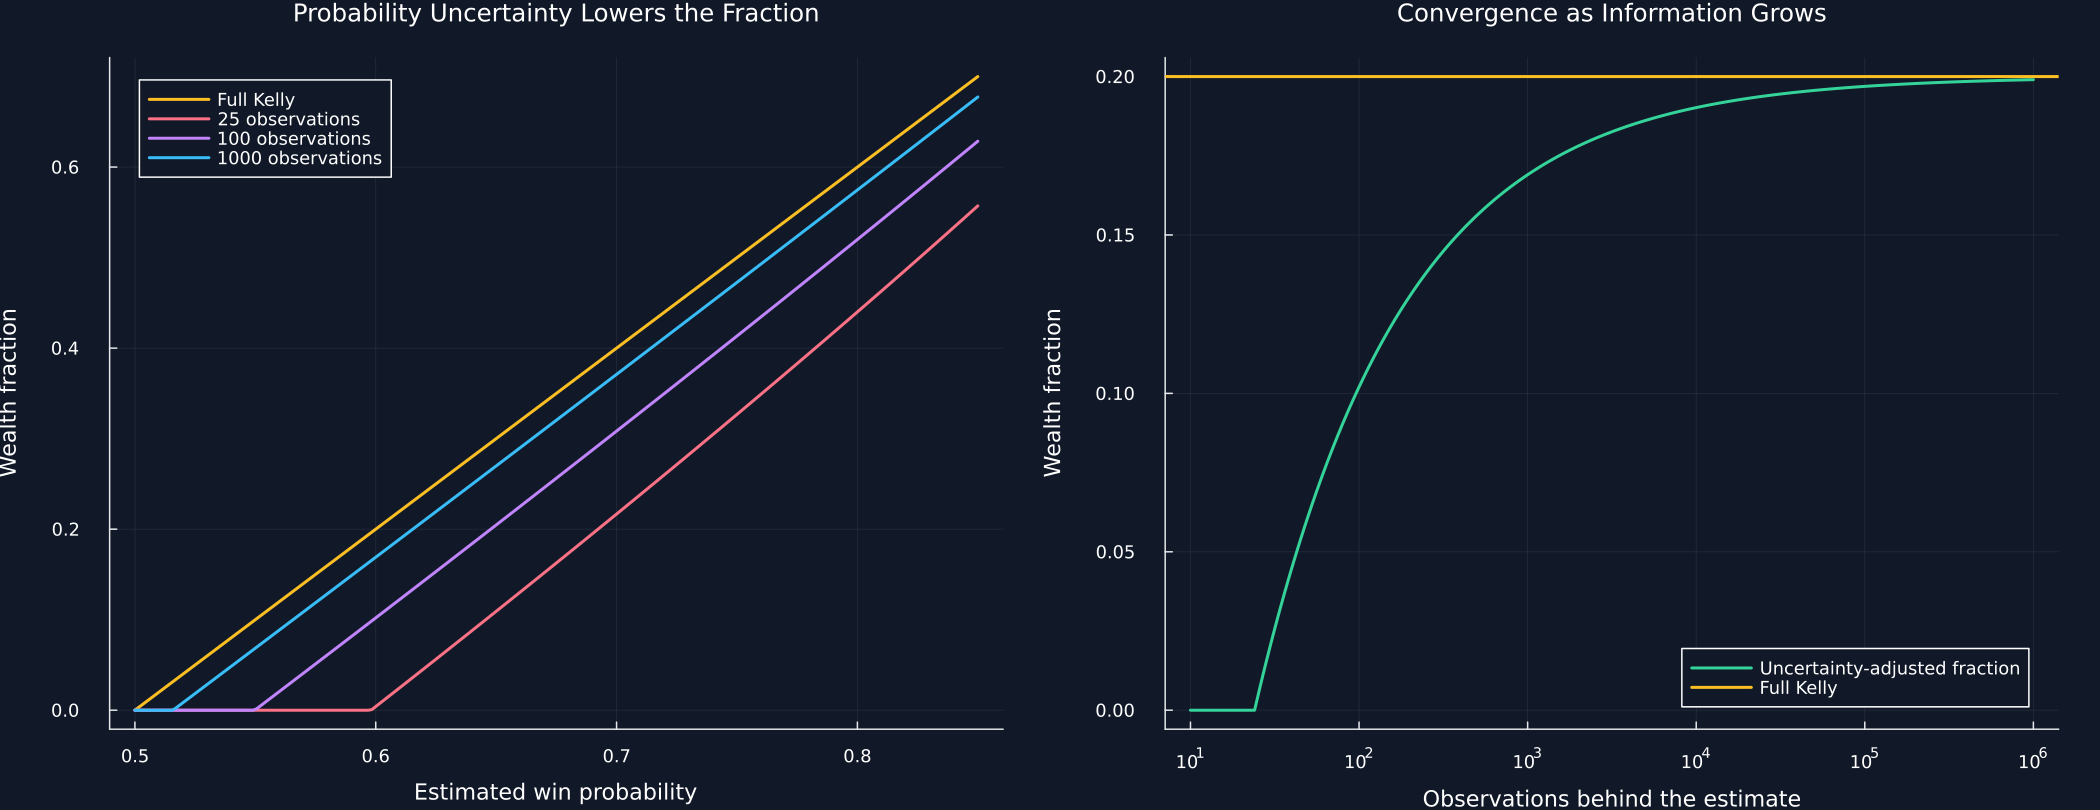

In [6]:
kelly_rows = [(probability=probability,observations=observations,full=kelly_bet_fraction(probability),robust=distributionally_robust_kelly_fraction(probability,observations)) for probability in [.50,.55,.60,.70,.80] for observations in [25,100,1000,1000000]]
kelly_sensitivity = DataFrame(kelly_rows)
rename!(kelly_sensitivity,["Win probability","Observations","Full Kelly fraction","Uncertainty-adjusted fraction"])
public_probability_quantiles = quantile(test_confidence,[.10,.25,.50,.75,.90])
public_kelly_summary = DataFrame("Probability quantile"=>["10 percent","25 percent","50 percent","75 percent","90 percent"],"Predicted-class probability"=>public_probability_quantiles,"Full Kelly fraction"=>kelly_bet_fraction(public_probability_quantiles),"Uncertainty-adjusted fraction"=>distributionally_robust_kelly_fraction(public_probability_quantiles,length(train)))
table(kelly_sensitivity,"kelly_sensitivity","Full and uncertainty-adjusted Kelly fractions.")
table(public_kelly_summary,"public_kelly_summary","Kelly fractions at probability quantiles from the public test block.")
probability_axis = collect(range(.5,.85;length=250))
curves = DataFrame(probability=probability_axis,full=kelly_bet_fraction(probability_axis))
p1 = plot(probability_axis,curves.full;color=palette.amber,label="Full Kelly",xlabel="Estimated win probability",ylabel="Wealth fraction",title="Probability Uncertainty Lowers the Fraction",legend=:topleft)
for (observations,color) in zip([25,100,1000],[palette.rose,violet,palette.cyan])
    values = distributionally_robust_kelly_fraction(probability_axis,observations)
    curves[!,"n_"*string(observations)] = values
    plot!(p1,probability_axis,values;color,label=string(observations)*" observations")
end
observation_axis = unique(floor.(Int,10 .^collect(range(1.,6.;length=240))))
convergence = [distributionally_robust_kelly_fraction(.60,observations) for observations in observation_axis]
save_data(curves,paths,"kelly_probability_curves")
save_data(DataFrame(observations=observation_axis,robust=convergence,full=fill(kelly_bet_fraction(.60),length(convergence))),paths,"kelly_convergence")
p2 = plot(observation_axis,convergence;xscale=:log10,xticks=10. .^(1:6),color=palette.green,label="Uncertainty-adjusted fraction",xlabel="Observations behind the estimate",ylabel="Wealth fraction",title="Convergence as Information Grows",legend=:bottomright)
hline!(p2,[kelly_bet_fraction(.60)];color=palette.amber,label="Full Kelly")
save_figure(plot(p1,p2;layout=(1,2),size=(1400,540)),paths,"robust_kelly_fractions")


## Tests

In [7]:
@assert length(prices)==2330
@assert length(y)==2271
@assert length.([train,calibration,test])==[1362,454,455]
@assert size(calibration_summary)==(4,6)
@assert brier_score(repaired_test,test_outcomes)<brier_score(distorted_test,test_outcomes)
@assert expected_calibration_error(repaired_test,test_outcomes,10)<expected_calibration_error(distorted_test,test_outcomes,10)
@assert isapprox(probability_bet_size([0.,0.],[1.,-1.]),[0.,0.];atol=1e-12)
@assert isapprox(probability_bet_size(fill(quantile(Normal(),.75),2),[1.,-1.]),[.5,-.5])
controlled_average = average_bet_sizes(0:9,[0,2,8],[5,7,9],[1.,.5,-1.])
@assert isapprox(controlled_average,[1.,1.,.75,.75,.75,.75,.5,.5,-1.,-1.])
controlled_dates = Date(2020,1,1).+Day.(0:9)
controlled_strategy = strategy_bet_sizing(controlled_dates,controlled_dates[[1,3,9]],controlled_dates[[6,8,10]],[1,1,-1],[0.,quantile(Normal(),.75),quantile(Normal(),.75)])
@assert isapprox(controlled_strategy,[0.,0.,.25,.25,.25,.25,.5,.5,-.5,-.5])
@assert generated_dates==active_dates
@assert generated_active==discrete_active
@assert isclose(bet_size_sigmoid(1.,.5),.4472135954999579)
@assert isclose(compute_sigmoid_width(.5,bet_size_sigmoid(1.,.5)),1.)
@assert target_position(1.,10.5,10.,100)==44
@assert isclose(width,10.803324099723)
@assert target_position(width,115.,100.,100)==97
@assert isclose(limit_price(97,0,115.,width,100),112.36573855883363)
@assert isclose(inverse_price(115.,width,.5),113.10263340389898)
@assert isclose(kelly_bet_fraction(.60),.20)
@assert kelly_bet_fraction(.50)==0.
@assert distributionally_robust_kelly_fraction(.60,40)<distributionally_robust_kelly_fraction(.60,1000000)<=kelly_bet_fraction(.60)
@assert isfile(joinpath(paths.figures,"calibration_reliability.pdf"))
@assert isfile(joinpath(paths.figures,"probability_size_map.pdf"))
@assert isfile(joinpath(paths.figures,"active_signal_path.pdf"))
@assert isfile(joinpath(paths.figures,"dynamic_sigmoid_positions.pdf"))
@assert isfile(joinpath(paths.figures,"robust_kelly_fractions.pdf"))
@assert base_model.converged
@assert raw_calibrator.converged
@assert distortion_calibrator.converged
table(DataFrame("Check"=>["Public file identity","Time-ordered split","Known overconfidence repaired","Probability-size mapping","Overlapping averages","Dynamic position inverse","Uncertainty-adjusted fraction"],"Status"=>fill("Pass",7)),"calibration_checks","Calibration and position checks.")


Row,Check,Status
,String,String
1,Public file identity,Pass
2,Time-ordered split,Pass
3,Known overconfidence repaired,Pass
4,Probability-size mapping,Pass
5,Overlapping averages,Pass
6,Dynamic position inverse,Pass
7,Uncertainty-adjusted fraction,Pass
